In [ ]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import warnings; warnings.filterwarnings('ignore')
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 50)
SEED = 42

from google.colab import files
import zipfile
uploaded = files.upload()                      # upload the zip
zip_name = next(iter(uploaded))
with zipfile.ZipFile(zip_name) as z:
    z.extractall('.'); print(z.namelist())

train = pd.read_csv('train.csv')
test  = pd.read_csv('test.csv')
sub   = pd.read_csv('sample_submission.csv')

ID, TARGET = 'id', 'price'
print(train.shape, test.shape, sub.shape)
display(train.head())

Saving domestic-flight-price-prediction-challenge (1).zip to domestic-flight-price-prediction-challenge (1).zip
['sample_submission.csv', 'test.csv', 'train.csv']
(15589, 12) (3898, 11) (3898, 2)


,id,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,flight_class,duration,days_left,price
0,1,Wayfarer Aviation,IX 1070,Metropolis,Evening,zero,Night,Springfield,Economy,NaN,18,8909
1,2,Oceanic Airlines,6E 285,Los Santos,Night,zero,Night,Springfield,Economy,1.33,38,5115
2,3,Wayfarer Aviation,AI 2641,Night City,Evening,zero,Night,Springfield,Business,2.08,13,35247
3,4,Oceanic Airlines,6E 6704,Night City,Afternoon,zero,Evening,Metropolis,Economy,2.25,5,6457
4,5,Oceanic Airlines,6E 234,Hill Valley,Evening,one,Night,Springfield,Economy,4.83,21,6842


In [ ]:
FEATURES = [c for c in test.columns if c != ID]
CAT_COLS = ['airline', 'flight', 'source_city', 'departure_time', 'stops',
            'arrival_time', 'destination_city', 'flight_class']
NUM_COLS = ['duration', 'days_left']

print('Same feature columns:', set(FEATURES) == set(train.columns) - {ID, TARGET})
print('\nMissing values (% of rows):')
display(pd.DataFrame({'train %': train[FEATURES].isna().mean()*100,
                      'test %':  test[FEATURES].isna().mean()*100}).round(1))

print('Unique values per categorical column:')
print(train[CAT_COLS].nunique().to_string())

print('\nFull duplicate rows (incl. price):', train.duplicated(subset=FEATURES + [TARGET]).sum())
print('Same features, different price:',
      train.duplicated(subset=FEATURES).sum() - train.duplicated(subset=FEATURES + [TARGET]).sum())

Same feature columns: True

Missing values (% of rows):


,train %,test %
airline,19.8,20.5
flight,0.0,0.0
source_city,0.0,0.0
departure_time,0.0,0.0
stops,0.0,0.0
arrival_time,0.0,0.0
destination_city,0.0,0.0
flight_class,0.0,0.0
duration,19.9,19.9
days_left,0.0,0.0


Unique values per categorical column:
airline               18
flight              1070
source_city            6
departure_time         6
stops                  3
arrival_time           6
destination_city       6
flight_class           2

Full duplicate rows (incl. price): 279
Same features, different price: 35


In [ ]:
train = train.drop_duplicates(subset=FEATURES + [TARGET]).reset_index(drop=True)
print('Train after removing exact duplicates:', train.shape)

# flight prefix (e.g. '6E', 'AI') identifies the airline
for df in (train, test):
    df['flight_prefix'] = df['flight'].str.split().str[0]

known = train.dropna(subset=['airline'])
print('Prefixes mapping to more than one airline:',
      (known.groupby('flight_prefix')['airline'].nunique() > 1).sum())
display(known.groupby('flight_prefix')['airline'].agg(lambda s: s.value_counts().index[0])
             .rename('airline').to_frame().T)

# same flight + route + stops -> same duration?
key = ['flight', 'source_city', 'destination_city', 'stops']
spread = train.dropna(subset=['duration']).groupby(key)['duration'].nunique()
print(f'Flight-route groups with a single duration value: {(spread == 1).mean():.1%}')

Train after removing exact duplicates: (15310, 12)
Prefixes mapping to more than one airline: 0


flight_prefix,6E,9I,AI,EK,EY,FZ,GF,IX,KU,MH,QP,QR,RA,S5,SG,SQ,TG,UL,WY
airline,Oceanic Airlines,Massive Dynamic,Wayfarer Aviation,Stark Aviation,Nakatomi Airlines,Initech Air,Aperture Aviation,Wayfarer Aviation,Black Mesa Air,Virtucon,Sandpiper Air,Vault-Tec Air,Cyberdyne Flights,Hooli Airways,Vandelay Aviation,Weyland Air,Wayne Enterprises Air,Ajira Airways,Omni Consumer Flights


Flight-route groups with a single duration value: 81.8%


In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin

class FlightImputer(BaseEstimator, TransformerMixin):
    """Fills airline from the flight prefix and duration from the same flight/route.
    All lookup tables are learned in fit() -> only from the training fold (no leakage)."""
    FLIGHT_KEY = ['flight', 'source_city', 'destination_city', 'stops']
    ROUTE_KEY  = ['source_city', 'destination_city', 'stops']

    def fit(self, X, y=None):
        X = X.copy()
        X['flight_prefix'] = X['flight'].str.split().str[0]
        self.airline_map_ = (X.dropna(subset=['airline'])
                              .groupby('flight_prefix')['airline'].agg(lambda s: s.mode()[0]))
        d = X.dropna(subset=['duration'])
        self.dur_flight_ = d.groupby(self.FLIGHT_KEY)['duration'].median()
        self.dur_route_  = d.groupby(self.ROUTE_KEY)['duration'].median()
        self.dur_global_ = d['duration'].median()
        return self

    def _lookup(self, X, table, key):
        idx = pd.MultiIndex.from_frame(X[key])
        return pd.Series(table.reindex(idx).values, index=X.index)

    def transform(self, X):
        X = X.copy()
        prefix = X['flight'].str.split().str[0]
        X['airline'] = X['airline'].fillna(prefix.map(self.airline_map_)).fillna('Unknown')
        X['duration'] = (X['duration']
                         .fillna(self._lookup(X, self.dur_flight_, self.FLIGHT_KEY))
                         .fillna(self._lookup(X, self.dur_route_, self.ROUTE_KEY))
                         .fillna(self.dur_global_))
        return X

imp = FlightImputer().fit(train[FEATURES])
tr_f, te_f = imp.transform(train[FEATURES]), imp.transform(test[FEATURES])
print('Missing after imputation (train / test):')
print(pd.DataFrame({'train': tr_f[['airline','duration']].isna().sum(),
                    'test':  te_f[['airline','duration']].isna().sum()}))
print('\nTest airlines filled as "Unknown":', (te_f['airline'] == 'Unknown').sum())

# sanity check: hide known durations, re-impute them, compare to the truth
known = train.dropna(subset=['duration']).sample(2000, random_state=SEED)
hidden = known[FEATURES].assign(duration=np.nan)
err = (FlightImputer().fit(train.drop(known.index)[FEATURES]).transform(hidden)['duration']
       - known['duration']).abs()
print(f'Duration imputation check: median abs error {err.median():.2f} h, '
      f'within 0.5 h: {(err <= 0.5).mean():.1%}')

Missing after imputation (train / test):
          train  test
airline       0     0
duration      0     0

Test airlines filled as "Unknown": 0
Duration imputation check: median abs error 0.00 h, within 0.5 h: 95.1%


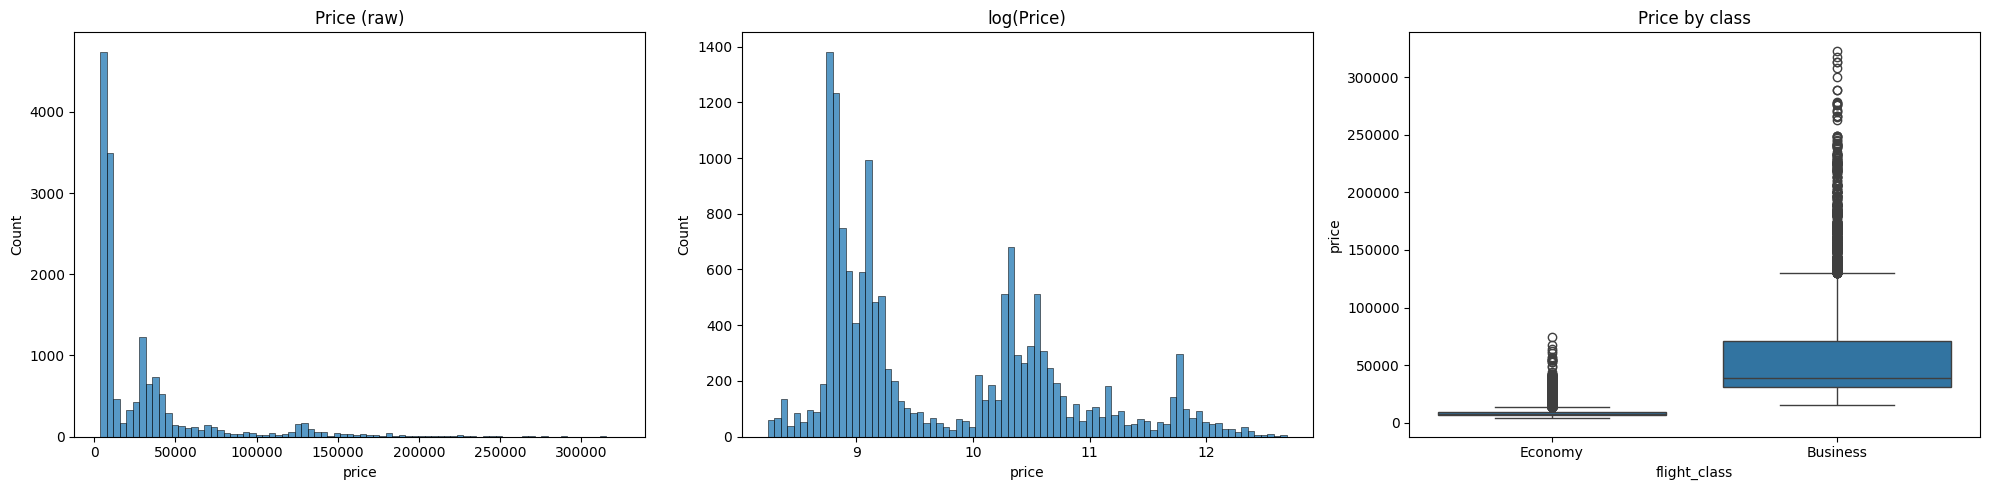

Skew raw: 2.7 | skew log: 0.72


,count,mean,std,min,25%,50%,75%,max
flight_class,,,,,,,,
Business,6249.0,60350.0,46675.0,15544.0,30767.0,38546.0,70580.0,323177.0
Economy,9061.0,8810.0,4670.0,3801.0,6740.0,7586.0,9301.0,74691.0


R² using flight_class alone: 0.416


In [ ]:
eda = imp.transform(train[FEATURES]).assign(price=train[TARGET])

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
sns.histplot(eda['price'], bins=80, ax=axes[0]); axes[0].set_title('Price (raw)')
sns.histplot(np.log(eda['price']), bins=80, ax=axes[1]); axes[1].set_title('log(Price)')
sns.boxplot(data=eda, x='flight_class', y='price', ax=axes[2]); axes[2].set_title('Price by class')
plt.tight_layout(); plt.show()

print('Skew raw:', round(eda['price'].skew(), 2), '| skew log:', round(np.log(eda['price']).skew(), 2))
display(eda.groupby('flight_class')['price'].describe().round(0))

# R² of predicting just the class average
class_mean = eda.groupby('flight_class')['price'].transform('mean')
sse = ((eda['price'] - class_mean) ** 2).sum()
sst = ((eda['price'] - eda['price'].mean()) ** 2).sum()
print('R² using flight_class alone:', round(1 - sse / sst, 3))

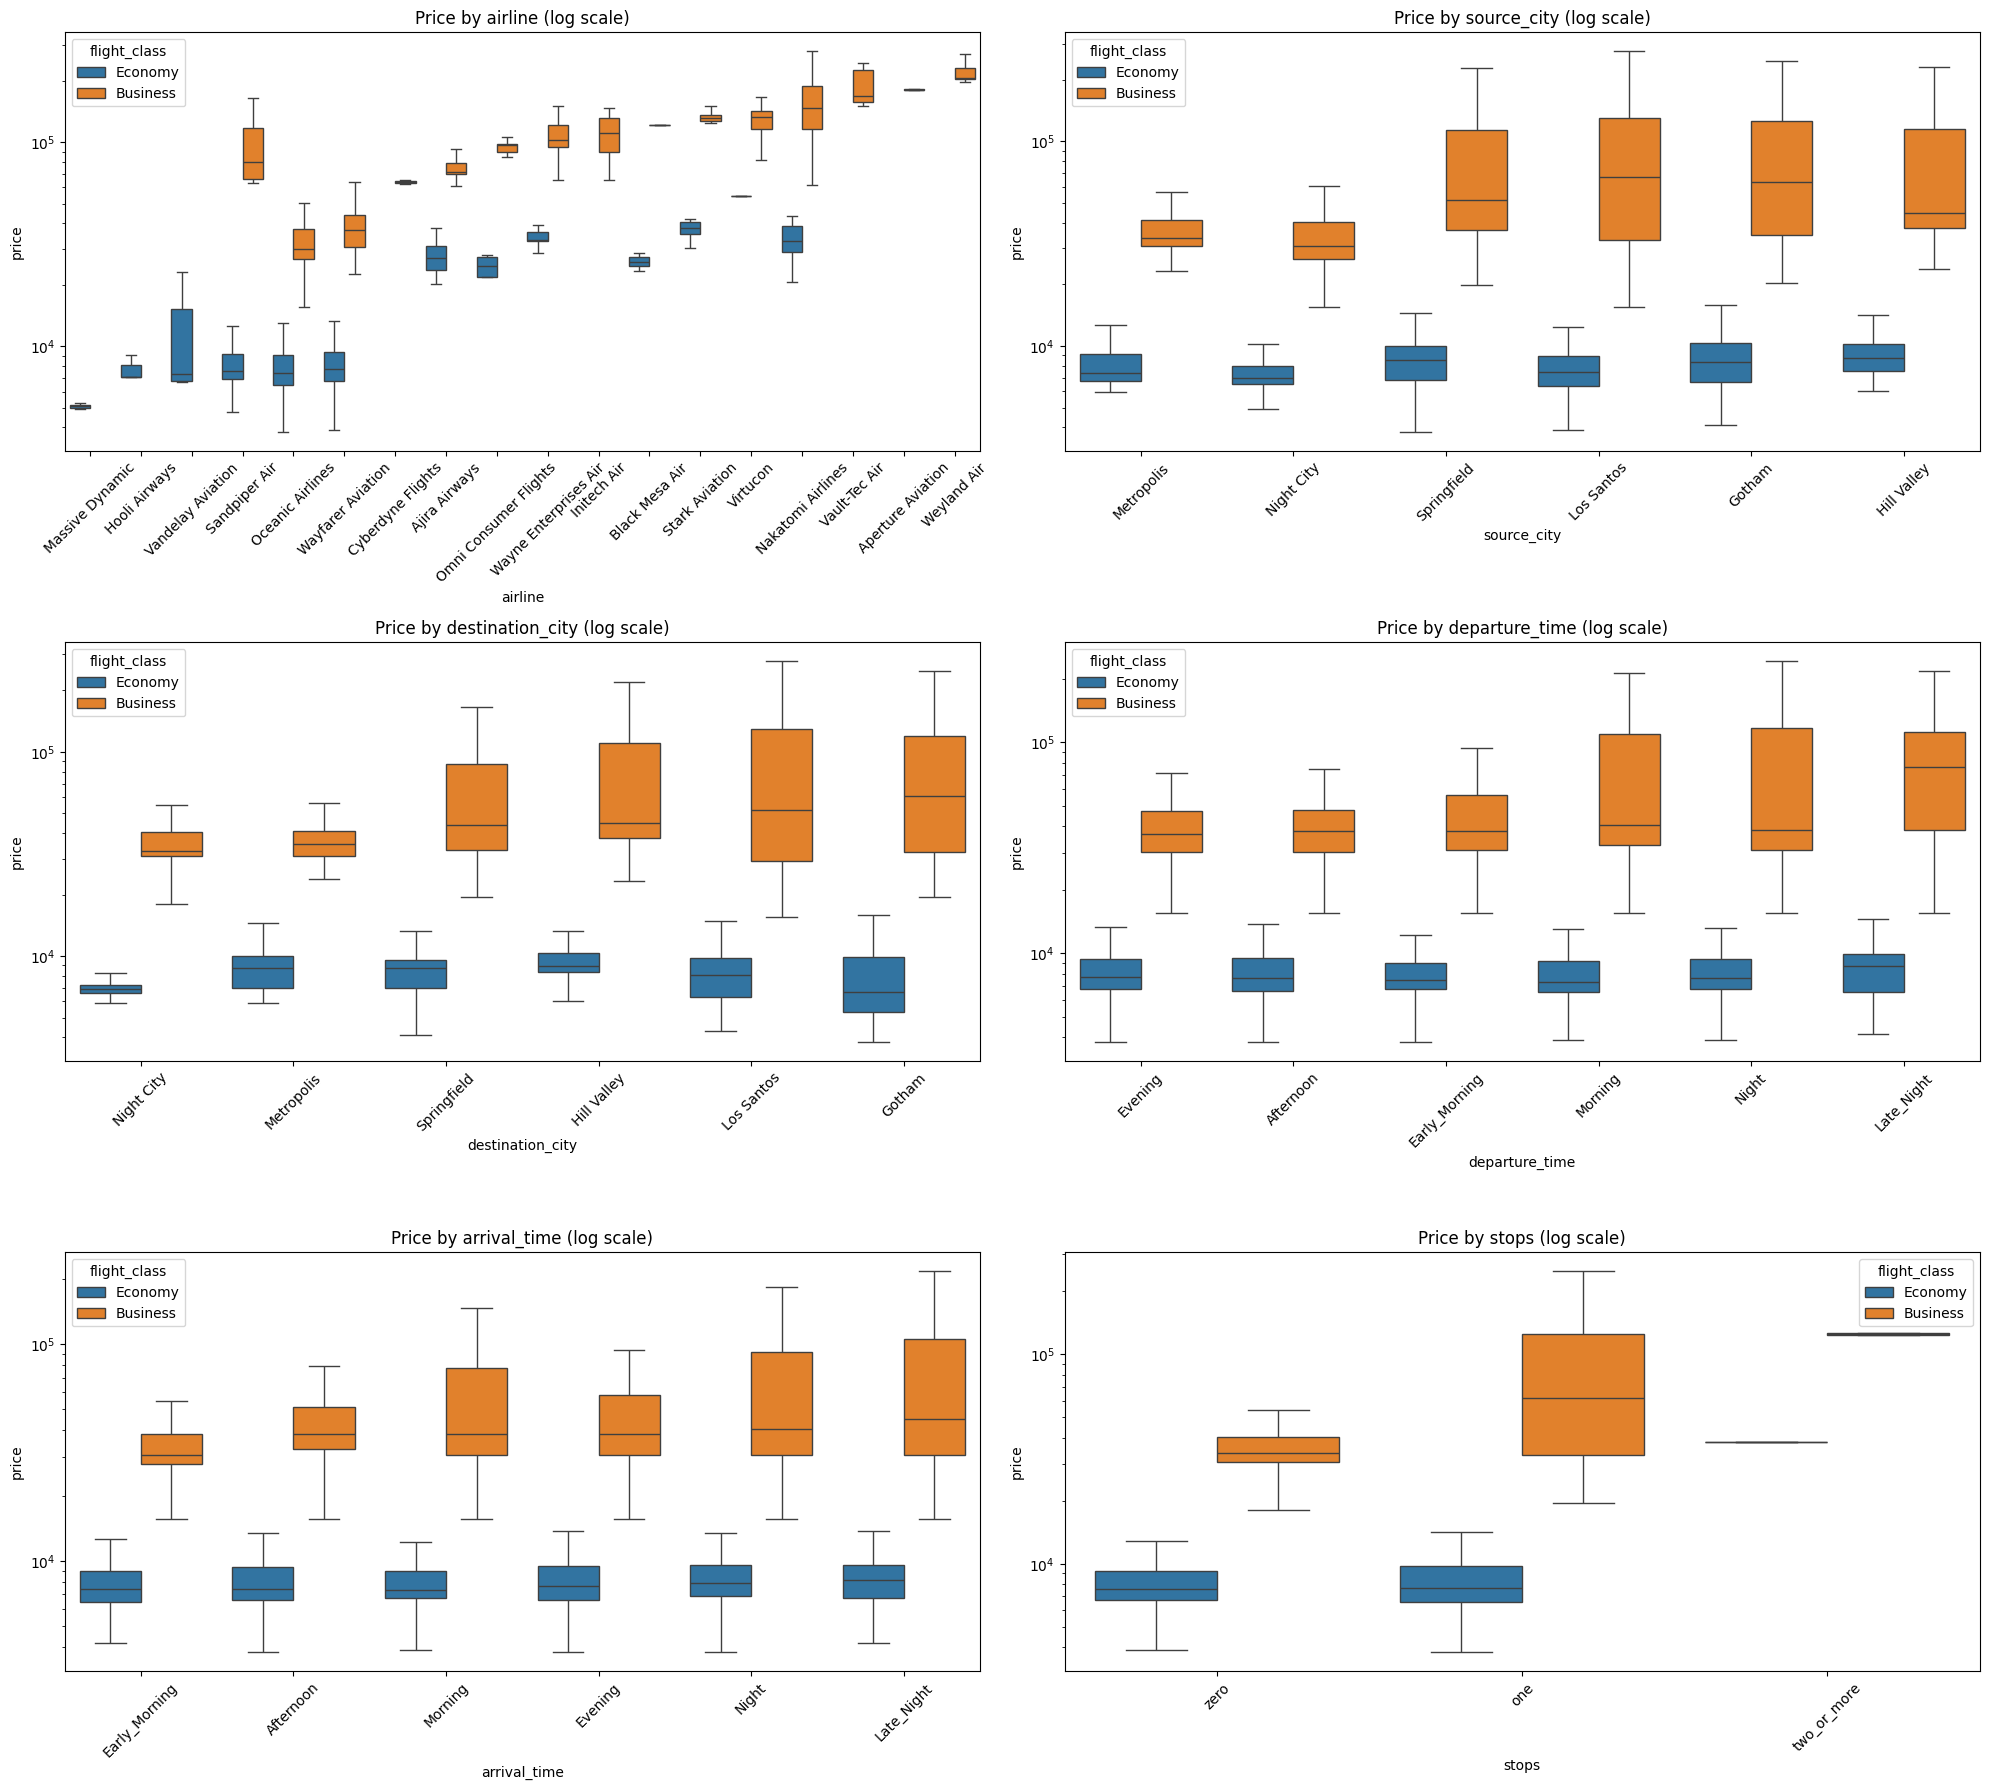

Row counts per airline and class:


flight_class,Business,Economy
airline,,
Wayfarer Aviation,3037,3298
Oceanic Airlines,1636,4618
Stark Aviation,399,39
Nakatomi Airlines,359,44
Ajira Airways,346,69
Wayne Enterprises Air,210,15
Virtucon,92,1
Vault-Tec Air,60,0
Aperture Aviation,31,0


In [ ]:
cat_plot = ['airline', 'source_city', 'destination_city', 'departure_time',
            'arrival_time', 'stops']

fig, axes = plt.subplots(3, 2, figsize=(20, 18))
for ax, col in zip(axes.flat, cat_plot):
    order = eda.groupby(col)['price'].median().sort_values().index
    sns.boxplot(data=eda, x=col, y='price', hue='flight_class', order=order,
                showfliers=False, ax=ax)
    ax.set_yscale('log'); ax.set_title(f'Price by {col} (log scale)')
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()

print('Row counts per airline and class:')
display(pd.crosstab(eda['airline'], eda['flight_class']).sort_values('Business', ascending=False))

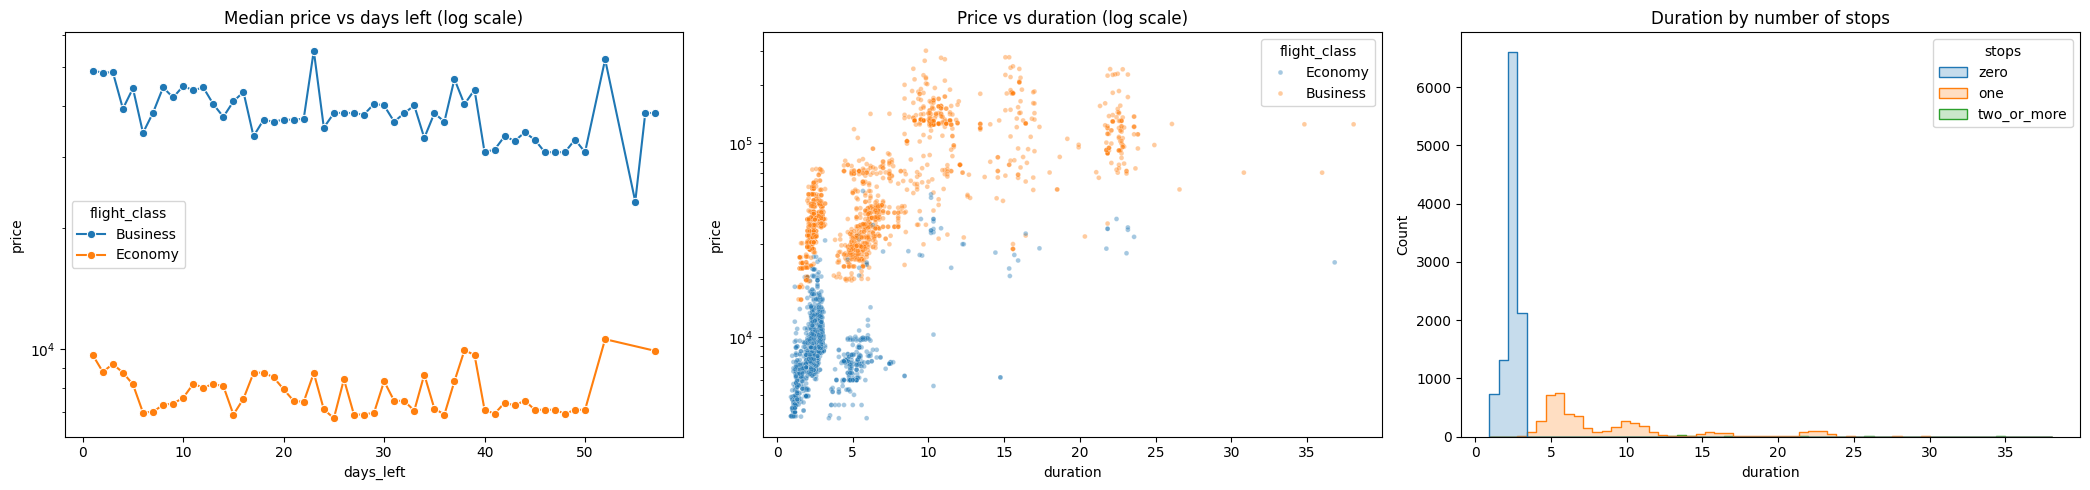

Economy   Spearman corr with log(price): days_left -0.007 | duration +0.447
Business  Spearman corr with log(price): days_left -0.106 | duration +0.684


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(21, 5))

trend = eda.groupby(['days_left', 'flight_class'])['price'].median().reset_index()
sns.lineplot(data=trend, x='days_left', y='price', hue='flight_class', marker='o', ax=axes[0])
axes[0].set_yscale('log'); axes[0].set_title('Median price vs days left (log scale)')

sns.scatterplot(data=eda.sample(4000, random_state=SEED), x='duration', y='price',
                hue='flight_class', alpha=0.4, s=12, ax=axes[1])
axes[1].set_yscale('log'); axes[1].set_title('Price vs duration (log scale)')

sns.histplot(data=eda, x='duration', hue='stops', bins=60, element='step', ax=axes[2])
axes[2].set_title('Duration by number of stops')
plt.tight_layout(); plt.show()

for cls in ['Economy', 'Business']:
    d = eda[eda['flight_class'] == cls]
    print(f"{cls:<9} Spearman corr with log(price): "
          f"days_left {d['days_left'].corr(np.log(d['price']), method='spearman'):+.3f} | "
          f"duration {d['duration'].corr(np.log(d['price']), method='spearman'):+.3f}")

In [ ]:
from sklearn.model_selection import RepeatedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import OrdinalEncoder
from sklearn.preprocessing import StandardScaler

X = train[FEATURES].copy()
y = train[TARGET].values
X_test = test[FEATURES].copy()

CAT = ['airline', 'source_city', 'destination_city',
       'departure_time', 'arrival_time', 'stops',
       'flight_class']
NUM = ['duration', 'days_left']


def linear_prep(min_freq=None):
    # one-hot categoricals + scaled numerics
    ohe = OneHotEncoder(
        handle_unknown='infrequent_if_exist',
        min_frequency=min_freq,
        sparse_output=False)
    return ColumnTransformer([
        ('cat', ohe, CAT),
        ('num', StandardScaler(), NUM)])


def tree_prep():
    # ordinal categoricals + raw numerics
    oe = OrdinalEncoder(
        handle_unknown='use_encoded_value',
        unknown_value=-1)
    return ColumnTransformer([
        ('cat', oe, CAT),
        ('num', 'passthrough', NUM)])


cv = RepeatedKFold(n_splits=5, n_repeats=3,
                   random_state=SEED)
results = {}


def evaluate(name, model):
    r = cross_validate(
        model, X, y, cv=cv, scoring='r2',
        return_train_score=True, n_jobs=-1)
    te = r['test_score']
    tr = r['train_score']
    results[name] = {
        'cv_r2': te.mean(),
        'cv_r2_std': te.std(),
        'train_r2': tr.mean(),
        'gap': tr.mean() - te.mean()}
    print(f"{name:<34} "
          f"CV R² {te.mean():.4f} ± {te.std():.4f} | "
          f"train {tr.mean():.4f} | "
          f"gap {tr.mean() - te.mean():+.4f}")


print('X:', X.shape, '| X_test:', X_test.shape)

X: (15310, 10) | X_test: (3898, 10)


In [ ]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge, Lasso
from sklearn.compose import TransformedTargetRegressor


def lin_pipe(model, min_freq=None):
    return Pipeline([
        ('impute', FlightImputer()),
        ('prep', linear_prep(min_freq)),
        ('model', model)])


evaluate('Dummy (mean)',
         lin_pipe(DummyRegressor()))
evaluate('Linear Regression',
         lin_pipe(LinearRegression()))
evaluate('Ridge (alpha=1)',
         lin_pipe(Ridge(alpha=1)))
evaluate('Lasso (alpha=10)',
         lin_pipe(Lasso(alpha=10, max_iter=20000)))

# same Ridge, but trained on log(price)
log_ridge = TransformedTargetRegressor(
    regressor=lin_pipe(Ridge(alpha=1)),
    func=np.log, inverse_func=np.exp)
evaluate('Ridge on log(price)', log_ridge)

Dummy (mean)                       CV R² -0.0004 ± 0.0004 | train 0.0000 | gap +0.0004
Linear Regression                  CV R² 0.8597 ± 0.0082 | train 0.8621 | gap +0.0024
Ridge (alpha=1)                    CV R² 0.8594 ± 0.0080 | train 0.8619 | gap +0.0026
Lasso (alpha=10)                   CV R² 0.8585 ± 0.0081 | train 0.8611 | gap +0.0025
Ridge on log(price)                CV R² 0.8419 ± 0.0113 | train 0.8449 | gap +0.0029


In [ ]:
from sklearn.preprocessing import PolynomialFeatures


def poly_pipe(alpha):
    return Pipeline([
        ('impute', FlightImputer()),
        ('prep', linear_prep()),
        ('poly', PolynomialFeatures(
            degree=2, include_bias=False)),
        ('model', Ridge(alpha=alpha))])


for a in [1, 3, 10, 30, 100]:
    evaluate(f'Poly2 + Ridge (alpha={a})',
             poly_pipe(a))

Poly2 + Ridge (alpha=1)            CV R² 0.9180 ± 0.0052 | train 0.9335 | gap +0.0155
Poly2 + Ridge (alpha=3)            CV R² 0.9189 ± 0.0052 | train 0.9327 | gap +0.0137
Poly2 + Ridge (alpha=10)           CV R² 0.9188 ± 0.0053 | train 0.9305 | gap +0.0117
Poly2 + Ridge (alpha=30)           CV R² 0.9159 ± 0.0055 | train 0.9260 | gap +0.0101
Poly2 + Ridge (alpha=100)          CV R² 0.9073 ± 0.0060 | train 0.9155 | gap +0.0083


In [ ]:
from sklearn.tree import DecisionTreeRegressor


def tree_pipe(model):
    return Pipeline([
        ('impute', FlightImputer()),
        ('prep', tree_prep()),
        ('model', model)])


evaluate('Tree (no limits)',
         tree_pipe(DecisionTreeRegressor(
             random_state=SEED)))

for depth in [6, 8, 10, 12]:
    for leaf in [5, 10, 20]:
        evaluate(f'Tree depth={depth} leaf={leaf}',
                 tree_pipe(DecisionTreeRegressor(
                     max_depth=depth,
                     min_samples_leaf=leaf,
                     random_state=SEED)))

Tree (no limits)                   CV R² 0.8707 ± 0.0146 | train 0.9993 | gap +0.1286
Tree depth=6 leaf=5                CV R² 0.8906 ± 0.0081 | train 0.8989 | gap +0.0084
Tree depth=6 leaf=10               CV R² 0.8885 ± 0.0085 | train 0.8968 | gap +0.0084
Tree depth=6 leaf=20               CV R² 0.8875 ± 0.0083 | train 0.8942 | gap +0.0067
Tree depth=8 leaf=5                CV R² 0.9077 ± 0.0088 | train 0.9216 | gap +0.0138
Tree depth=8 leaf=10               CV R² 0.9043 ± 0.0092 | train 0.9177 | gap +0.0134
Tree depth=8 leaf=20               CV R² 0.8998 ± 0.0091 | train 0.9103 | gap +0.0106
Tree depth=10 leaf=5               CV R² 0.9111 ± 0.0083 | train 0.9351 | gap +0.0239
Tree depth=10 leaf=10              CV R² 0.9066 ± 0.0086 | train 0.9280 | gap +0.0214
Tree depth=10 leaf=20              CV R² 0.9007 ± 0.0082 | train 0.9164 | gap +0.0157
Tree depth=12 leaf=5               CV R² 0.9085 ± 0.0083 | train 0.9453 | gap +0.0368
Tree depth=12 leaf=10              CV R² 0.9056 ± 0.00

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import HistGradientBoostingRegressor

rf = RandomForestRegressor(
    n_estimators=200, max_depth=14,
    min_samples_leaf=5, n_jobs=-1,
    random_state=SEED)
evaluate('Random Forest (d14, leaf5)',
         tree_pipe(rf))

# first 7 columns after tree_prep are categorical
hgb = HistGradientBoostingRegressor(
    max_iter=400, learning_rate=0.05,
    max_depth=6, min_samples_leaf=20,
    l2_regularization=1.0,
    categorical_features=list(range(7)),
    random_state=SEED)
evaluate('Gradient Boosting (d6, leaf20)',
         tree_pipe(hgb))

Random Forest (d14, leaf5)         CV R² 0.9230 ± 0.0070 | train 0.9522 | gap +0.0292
Gradient Boosting (d6, leaf20)     CV R² 0.9257 ± 0.0069 | train 0.9451 | gap +0.0193


In [ ]:
from sklearn.ensemble import VotingRegressor

best_poly = poly_pipe(10)
best_hgb = tree_pipe(hgb)

ensemble = VotingRegressor(
    [('poly', best_poly), ('hgb', best_hgb)],
    weights=[1, 2])
evaluate('Ensemble Poly-Ridge + GB (1:2)',
         ensemble)

summary = pd.DataFrame(results).T
display(summary.sort_values('cv_r2', ascending=False)
               .round(4))

Ensemble Poly-Ridge + GB (1:2)     CV R² 0.9270 ± 0.0062 | train 0.9432 | gap +0.0162


,cv_r2,cv_r2_std,train_r2,gap
Ensemble Poly-Ridge + GB (1:2),0.9270,0.0062,0.9432,0.0162
"Gradient Boosting (d6, leaf20)",0.9257,0.0069,0.9451,0.0193
"Random Forest (d14, leaf5)",0.9230,0.0070,0.9522,0.0292
Poly2 + Ridge (alpha=3),0.9189,0.0052,0.9327,0.0137
Poly2 + Ridge (alpha=10),0.9188,0.0053,0.9305,0.0117
Poly2 + Ridge (alpha=1),0.9180,0.0052,0.9335,0.0155
Poly2 + Ridge (alpha=30),0.9159,0.0055,0.9260,0.0101
Tree depth=10 leaf=5,0.9111,0.0083,0.9351,0.0239
Tree depth=12 leaf=5,0.9085,0.0083,0.9453,0.0368
Tree depth=8 leaf=5,0.9077,0.0088,0.9216,0.0138


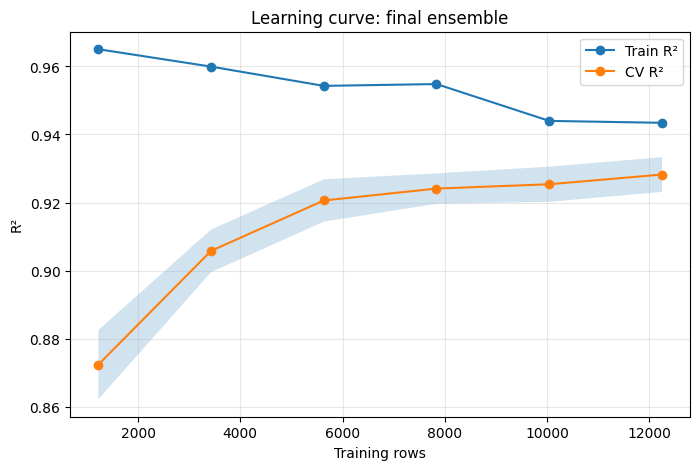

  1224 rows  train 0.9651  CV 0.8723  gap +0.0927
  3429 rows  train 0.9600  CV 0.9058  gap +0.0542
  5634 rows  train 0.9543  CV 0.9206  gap +0.0337
  7838 rows  train 0.9548  CV 0.9241  gap +0.0307
 10043 rows  train 0.9440  CV 0.9254  gap +0.0186
 12248 rows  train 0.9434  CV 0.9282  gap +0.0152


In [ ]:
from sklearn.model_selection import learning_curve
from sklearn.model_selection import KFold

sizes, tr_sc, va_sc = learning_curve(
    ensemble, X, y,
    train_sizes=np.linspace(0.1, 1.0, 6),
    cv=KFold(5, shuffle=True, random_state=SEED),
    scoring='r2', n_jobs=-1)

tr_m, va_m = tr_sc.mean(1), va_sc.mean(1)
plt.figure(figsize=(8, 5))
plt.plot(sizes, tr_m, 'o-', label='Train R²')
plt.plot(sizes, va_m, 'o-', label='CV R²')
plt.fill_between(sizes, va_m - va_sc.std(1),
                 va_m + va_sc.std(1), alpha=0.2)
plt.xlabel('Training rows'); plt.ylabel('R²')
plt.title('Learning curve: final ensemble')
plt.legend(); plt.grid(alpha=0.3); plt.show()

for s, a, b in zip(sizes, tr_m, va_m):
    print(f'{s:>6} rows  train {a:.4f}  '
          f'CV {b:.4f}  gap {a - b:+.4f}')

In [ ]:
final_model = ensemble.fit(X, y)
pred = final_model.predict(X_test)

# safety: no price below the cheapest seen
pred = np.clip(pred, y.min(), None)

submission = pd.DataFrame(
    {ID: test[ID], TARGET: pred})

assert list(submission.columns) == list(sub.columns)
assert len(submission) == len(sub)
assert (submission[ID].values
        == sub[ID].values).all()
assert submission[TARGET].notna().all()

print('Predicted price summary (test):')
print(submission[TARGET].describe().round(0))
print('\nTrain price summary:')
print(pd.Series(y).describe().round(0))

submission.to_csv('submission_ensemble.csv',
                  index=False)
files.download('submission_ensemble.csv')

Predicted price summary (test):
count      3898.0
mean      29671.0
std       37842.0
min        3801.0
25%        7688.0
50%       10176.0
75%       37114.0
max      223068.0
Name: price, dtype: float64

Train price summary:
count     15310.0
mean      29847.0
std       39291.0
min        3801.0
25%        7201.0
50%       10183.0
75%       35426.0
max      323177.0
dtype: float64


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>